# UAS Big Data – Analisis EEG Pasien Gangguan Psikiatri (BRMH)
**Tools:** Python (pandas, numpy, scipy, scikit-learn, statsmodels, matplotlib, seaborn)  
**Dataset:** *EEG machine learning data BRMH* – rekaman EEG 945 pasien gangguan psikiatri dan kontrol sehat, berisi data demografi, diagnosis, 114 fitur *absolute power* (AB) dan 1.026 fitur *coherence* (COH) dari 19 elektroda × 6 pita frekuensi.

**Alur proyek:** data mentah → **audit & cleaning** → analisis data (EDA & uji statistik) → karakteristik Big Data (3V+) → regresi → prediksi → visualisasi → kesimpulan.


**Struktur folder yang diharapkan**
```
uas-eeg/
├── data/raw/EEG_machinelearing_data_BRMH.csv   ← data mentah (tidak diubah)
├── data/clean/                                 ← hasil cleaning dibuat otomatis
├── figures/                                    ← grafik dibuat otomatis
└── UAS_EEG_BigData.ipynb
```

In [1]:
import os, time, warnings, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import statsmodels.api as sm, statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from scipy import stats
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold, RepeatedKFold,
                                     cross_val_score, cross_val_predict, permutation_test_score)
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, LogisticRegressionCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, roc_auc_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay, balanced_accuracy_score, accuracy_score)
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RS = 42
RAW   = "data/raw/EEG.machinelearing_data_BRMH.csv"
CLEAN = "data/clean"; FIG = "figures"
os.makedirs(CLEAN, exist_ok=True); os.makedirs(FIG, exist_ok=True)
def save(name): plt.savefig(f"{FIG}/{name}.png", dpi=150, bbox_inches="tight")

raw = pd.read_csv(RAW)          # DATA MENTAH – tidak pernah ditimpa
print("Data mentah:", raw.shape)
raw.iloc[:5, :10]

Data mentah: (945, 1149)


,no.,sex,age,eeg.date,education,IQ,main.disorder,specific.disorder,AB.A.delta.a.FP1,AB.A.delta.b.FP2
0,1,M,57.0,2012.8.30,NaN,NaN,Addictive disorder,Alcohol use disorder,35.998557,21.717375
1,2,M,37.0,2012.9.6,6.0,120.0,Addictive disorder,Alcohol use disorder,13.425118,11.002916
2,3,M,32.0,2012.9.10,16.0,113.0,Addictive disorder,Alcohol use disorder,29.941780,27.544684
3,4,M,35.0,2012.10.8,18.0,126.0,Addictive disorder,Alcohol use disorder,21.496226,21.846832
4,5,M,36.0,2012.10.18,16.0,112.0,Addictive disorder,Alcohol use disorder,37.775667,33.607679


# 1. Latar Belakang
Diagnosis gangguan psikiatri sampai kini bertumpu pada wawancara klinis. EEG menghasilkan data kuantitatif yang murah dan non-invasif, sehingga muncul minat memakainya sebagai pendukung skrining. Data EEG bersifat *wide* (ribuan fitur per pasien), heterogen, dan rawan artefak, sehingga cocok sebagai studi kasus Big Data.

**Masalah yang ingin diselesaikan**
1. Masalah kualitas data apa yang ada pada data mentah dan bagaimana penanganannya?
2. Pita frekuensi/area otak mana yang berbeda antara kontrol sehat dan pasien?
3. Faktor apa yang menjelaskan IQ (regresi), dan apakah EEG menambah daya prediksi?
4. Seberapa baik EEG memprediksi status sehat vs pasien dan jenis gangguan (prediksi)?

# 2. Pembersihan Data (Cleaning Data)
### 2.1 Struktur Data Mentah
Kolom terbagi menjadi: metadata pasien (8 kolom), **AB** = *absolute power* tiap elektroda per pita frekuensi (19 × 6 = 114), dan **COH** = *coherence* antar pasangan elektroda per pita (171 × 6 = 1.026).

In [2]:
meta_raw = list(raw.columns[:8])
ab_raw  = [c for c in raw.columns if c.startswith("AB.")]
coh_raw = [c for c in raw.columns if c.startswith("COH.")]
other   = [c for c in raw.columns if c not in meta_raw + ab_raw + coh_raw]
struct = pd.DataFrame({"Kelompok": ["Metadata pasien", "AB (absolute power)", "COH (coherence)", "Tak dikenal"],
                       "Jumlah kolom": [len(meta_raw), len(ab_raw), len(coh_raw), len(other)],
                       "Contoh": [", ".join(meta_raw[:3]) + ", ...", ab_raw[0], coh_raw[0], ", ".join(other)]})
display(struct)

,Kelompok,Jumlah kolom,Contoh
0,Metadata pasien,8,"no., sex, age, ..."
1,AB (absolute power),114,AB.A.delta.a.FP1
2,COH (coherence),1026,COH.A.delta.a.FP1.b.FP2
3,Tak dikenal,1,Unnamed: 122


### 2.2 Memastikan Kualitas Data (sebelum cleaning)

In [3]:
print(f"Ukuran: {raw.shape} | memori: {raw.memory_usage(deep=True).sum()/1e6:.1f} MB")
miss = raw.isna().sum(); miss = miss[miss > 0].to_frame("Jumlah missing"); miss["% baris"] = (miss.iloc[:,0]/len(raw)*100).round(1)
print("\n[1] Kolom dengan missing value:"); display(miss)

print("[2] Duplikat baris penuh:", int(raw.duplicated().sum()), "| duplikat nomor pasien:", int(raw['no.'].duplicated().sum()))

dup_ab = raw[raw.duplicated(subset=ab_raw, keep=False)].sort_values(ab_raw[0])
print("\n[3] Pasien berbeda dengan 114 nilai AB IDENTIK (mustahil terjadi alami):")
display(dup_ab[['no.','sex','age','eeg.date','main.disorder']])

d = pd.to_datetime(raw['eeg.date'], format='%Y.%m.%d', errors='coerce')
print("[4] Tanggal EEG yang gagal di-parse:"); display(raw.loc[d.isna(), ['no.','eeg.date']])

print("[5] Label specific.disorder:"); print(raw['specific.disorder'].value_counts().to_string())

print("\n[6] Koherensi bernilai persis 100 (koherensi sempurna antar dua elektroda = artefak):",
      int((raw[coh_raw] >= 100).sum().sum()), "sel di", int((raw[coh_raw] >= 100).any(axis=1).sum()), "baris")
print("[7] Skewness median fitur AB:", round(raw[ab_raw].skew().median(), 2), "(sangat miring ke kanan)")
print("[8] Rentang: usia", raw.age.min(), "-", raw.age.max(), "| IQ", raw.IQ.min(), "-", raw.IQ.max(),
      "| education", raw.education.min(), "-", raw.education.max(), "| AB min", round(raw[ab_raw].min().min(),3),
      "| COH min", raw[coh_raw].min().min())

Ukuran: (945, 1149) | memori: 8.9 MB

[1] Kolom dengan missing value:


,Jumlah missing,% baris
education,15,1.6
IQ,13,1.4
Unnamed: 122,945,100.0


[2] Duplikat baris penuh: 0 | duplikat nomor pasien: 0

[3] Pasien berbeda dengan 114 nilai AB IDENTIK (mustahil terjadi alami):


,no.,sex,age,eeg.date,main.disorder
204,205,F,21.0,2017.2.3,Healthy control
205,206,F,23.0,2017.2.7,Healthy control
225,226,M,20.0,2016.9.13,Addictive disorder
943,944,M,24.0,2014.9.20,Healthy control
263,264,M,37.0,2015.6.24,Obsessive compulsive disorder
264,265,M,32.0,2015.6.24,Obsessive compulsive disorder


[4] Tanggal EEG yang gagal di-parse:


,no.,eeg.date
584,585,2018.4.9 0:00
734,735,2013.4.18 0:00
839,840,2015.12.30 0:00
901,902,2014.1.7 0:00


[5] Label specific.disorder:
specific.disorder
Depressive disorder               199
Schizophrenia                     117
Healthy control                    95
Alcohol use disorder               93
Behavioral addiction disorder      93
Bipolar disorder                   67
Panic disorder                     59
Posttraumatic stress disorder      52
Social anxiety disorder            48
Obsessive compulsitve disorder     46
Acute stress disorder              38
Adjustment disorder                38

[6] Koherensi bernilai persis 100 (koherensi sempurna antar dua elektroda = artefak): 24 sel di 2 baris
[7] Skewness median fitur AB: 3.37 (sangat miring ke kanan)
[8] Rentang: usia 18.0 - 71.88 | IQ 49.0 - 145.0 | education 0.0 - 20.0 | AB min 0.026 | COH min 1.7e-05


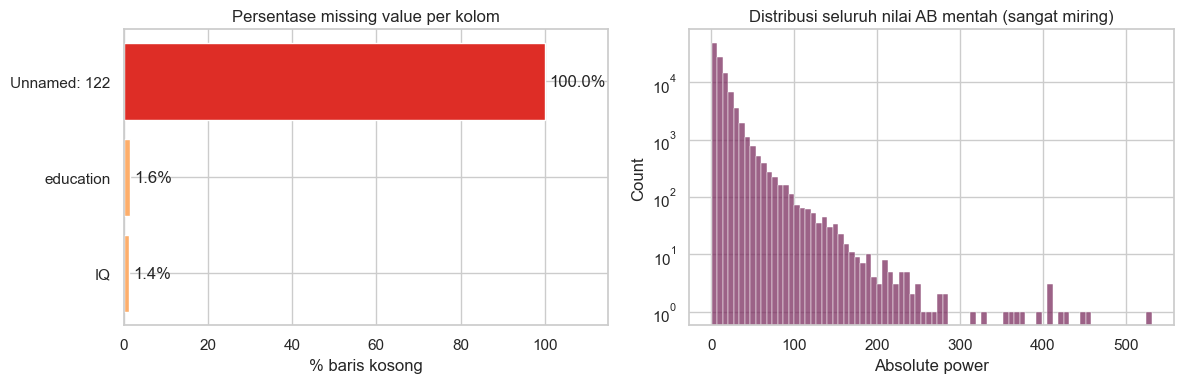

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
m = miss["% baris"].sort_values()
ax[0].barh(m.index, m.values, color=["#fdae6b" if v < 50 else "#de2d26" for v in m.values])
for i, v in enumerate(m.values): ax[0].text(v + 1, i, f"{v:.1f}%", va="center")
ax[0].set(title="Persentase missing value per kolom", xlabel="% baris kosong", xlim=(0, 115))
sns.histplot(raw[ab_raw].values.ravel(), bins=80, color="#7b2d5f", ax=ax[1])
ax[1].set(title="Distribusi seluruh nilai AB mentah (sangat miring)", xlabel="Absolute power", yscale="log")
plt.tight_layout(); save("00_audit_mentah"); plt.show()

**Temuan:** Data mentah ternyata memiliki beberapa masalah nyata:
1. Kolom `Unnamed: 122` kosong 100% (sisa format file).
2. `IQ` hilang pada 13 pasien dan `education` pada 15 pasien.
3. Label `Obsessive compulsitve disorder` salah ketik.
4. 4 tanggal EEG berformat tidak konsisten (ada akhiran " 0:00").
5. 3 pasang pasien berbeda memiliki 114 nilai AB persis sama; salah satu pasangan bahkan berlabel berbeda (gangguan adiktif vs kontrol sehat), sehingga tidak mungkin keduanya benar.
6. 24 nilai koherensi persis 100 pada 2 pasien, tanda artefak rekaman.
7. Nilai AB sangat miring ke kanan, sehingga dibutuhkan transformasi sebelum dimodelkan.
8. Nama kolom memakai titik dan sisipan huruf, tidak ramah untuk analisis dan BI.

### 2.3 Proses cleaning (setiap langkah dicatat)

In [5]:
df = raw.copy()
clog = []   # catatan cleaning
def log(masalah, tindakan, dampak): clog.append({"Masalah": masalah, "Tindakan": tindakan, "Dampak": dampak})

# --- 1. Hapus kolom kosong
n_before = df.shape[1]
empty_cols = [c for c in df.columns if df[c].isna().all()]
df = df.drop(columns=empty_cols)
log("Kolom kosong 100% (Unnamed: 122)", "Kolom dihapus", f"{len(empty_cols)} kolom dibuang")

# --- 2. Rapikan nama kolom
def rename_col(c):
    p = c.split(".")
    if p[0] == "AB":  return f"AB_{p[2]}_{p[4]}"                 # AB.A.delta.a.FP1 -> AB_delta_FP1
    if p[0] == "COH": return f"COH_{p[2]}_{p[4]}_{p[6]}"         # COH.A.delta.a.FP1.b.FP2 -> COH_delta_FP1_FP2
    return c
meta_map = {"no.":"patient_id","sex":"sex","age":"age","eeg.date":"eeg_date","education":"education",
            "IQ":"iq","main.disorder":"main_disorder","specific.disorder":"specific_disorder"}
newcols = [meta_map.get(c) or rename_col(c) for c in df.columns]
assert len(set(newcols)) == len(newcols), "nama kolom baru tidak unik"
df.columns = newcols
AB  = [c for c in df.columns if c.startswith("AB_")]
COH = [c for c in df.columns if c.startswith("COH_")]
log("Nama kolom memakai titik & huruf sisipan", "Diubah ke snake_case (AB_delta_FP1, COH_delta_FP1_FP2)", f"{len(AB)+len(COH)} nama fitur dirapikan")

# --- 3. Perbaiki typo label
typo = (df["specific_disorder"] == "Obsessive compulsitve disorder").sum()
df["specific_disorder"] = df["specific_disorder"].replace({"Obsessive compulsitve disorder": "Obsessive compulsive disorder"})
log("Typo label 'compulsitve'", "Dikoreksi", f"{typo} baris diperbaiki")

# --- 4. Perbaiki format tanggal
bad_dates = (pd.to_datetime(df["eeg_date"], format="%Y.%m.%d", errors="coerce").isna()).sum()
df["eeg_date"] = pd.to_datetime(df["eeg_date"].str.replace(r"\s+0:00$", "", regex=True), format="%Y.%m.%d")
df["eeg_year"] = df["eeg_date"].dt.year
log("Format tanggal EEG tidak konsisten", "Akhiran ' 0:00' dibuang, dikonversi ke datetime, ditambah kolom eeg_year", f"{bad_dates} tanggal diperbaiki, 0 gagal")

# --- 5. Hapus pasien dengan vektor AB identik (dugaan salah salin; tak bisa ditentukan mana yang benar)
dup_mask = df.duplicated(subset=AB, keep=False)
dropped_ids = df.loc[dup_mask, "patient_id"].tolist()
df = df.loc[~dup_mask].reset_index(drop=True)
log("Pasien berbeda dengan 114 nilai AB identik (3 pasangan, 1 pasangan berlabel konflik)", "Kedua baris tiap pasangan dibuang karena tidak dapat ditentukan mana yang benar", f"{len(dropped_ids)} baris dibuang (ID: {dropped_ids})")

# --- 6. Artefak koherensi 100 -> NaN -> imputasi median kolom
art = (df[COH] >= 100)
n_art = int(art.values.sum()); n_art_rows = int(art.any(axis=1).sum())
df[COH] = df[COH].mask(art)
df[COH] = df[COH].fillna(df[COH].median())
log("Koherensi = 100 (artefak)", "Dijadikan NaN lalu diimputasi median kolom", f"{n_art} sel di {n_art_rows} pasien diperbaiki")

# --- 7. Missing IQ & education -> imputasi median + penanda
df["iq_imputed"] = df["iq"].isna(); df["education_imputed"] = df["education"].isna()
n_iq, n_ed = int(df["iq_imputed"].sum()), int(df["education_imputed"].sum())
df["iq"] = df["iq"].fillna(df["iq"].median()); df["education"] = df["education"].fillna(df["education"].median())
log("Missing IQ dan education (tersebar di beberapa diagnosis; education relatif lebih sering hilang pada OCD)", "Imputasi median global + kolom penanda iq_imputed / education_imputed", f"{n_iq} IQ & {n_ed} education diisi; baris IQ-imputasi dikeluarkan saat IQ jadi target regresi")

# --- 8. Validasi akhir
assert df[AB+COH].isna().sum().sum() == 0 and df[["age","iq","education"]].isna().sum().sum() == 0
assert (df[AB] > 0).all().all() and ((df[COH] >= 0) & (df[COH] < 100)).all().all()
assert df["patient_id"].is_unique and df["main_disorder"].nunique() == 7 and df["specific_disorder"].nunique() == 12
print("Validasi akhir lulus: tidak ada missing, semua AB > 0, COH dalam [0,100), ID unik, 7 gangguan utama, 12 gangguan spesifik")

Validasi akhir lulus: tidak ada missing, semua AB > 0, COH dalam [0,100), ID unik, 7 gangguan utama, 12 gangguan spesifik


### 2.4 Outlier & distorsi skala: uji strategi

Nilai AB sangat miring (skew median ≈ 3,4), sehingga aturan IQR menandai hampir separuh pasien sebagai pencilan padahal itu variasi alami. Tiga strategi diuji dengan model yang sama (Logistic Regression ter-regularisasi, AUC validasi silang 5-fold untuk sehat vs pasien).

Skewness median : mentah 3.37  ->  log10 0.17
Sel pencilan IQR: mentah 5.9%  ->  log10 1.0%
Pasien dengan >=1 pencilan: mentah 531  ->  log10 199


,Jumlah pasien,AUC sehat vs pasien (CV)
Strategi,,
Mentah (µV²),939,0.752
log10,939,0.770
log10 + winsorize 1–99%,939,0.770
log10 + buang 45 pasien pencilan berat,894,0.777


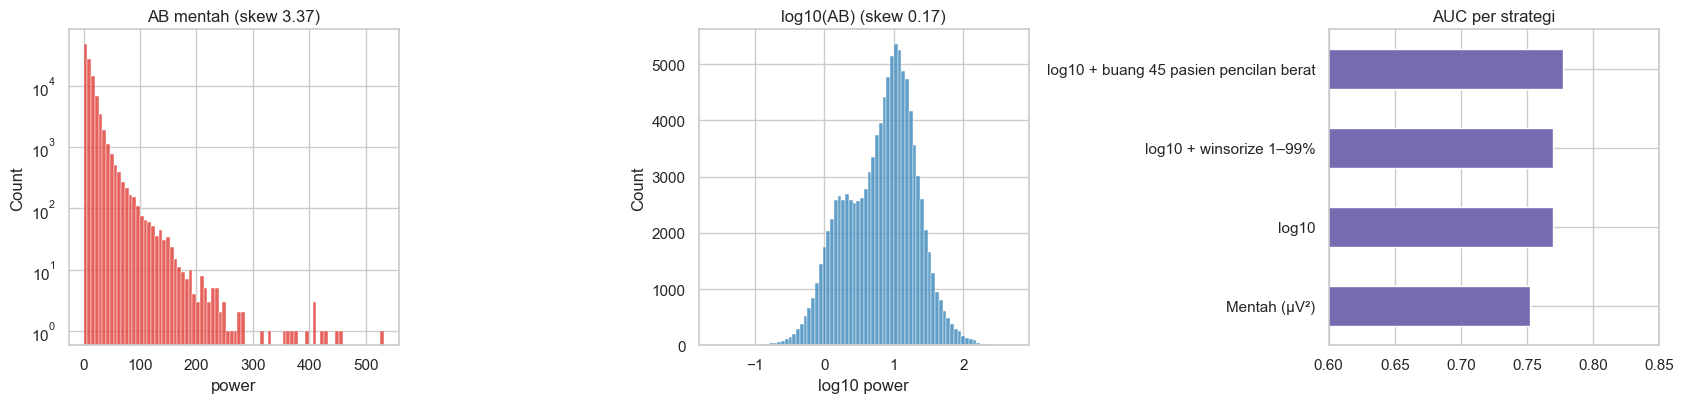

In [6]:
def iqr_out(X):
    q1, q3 = X.quantile(.25), X.quantile(.75); i = q3 - q1
    return (X < q1 - 1.5*i) | (X > q3 + 1.5*i)
A = df[AB]; L = np.log10(A)
o_raw, o_log = iqr_out(A), iqr_out(L)
print(f"Skewness median : mentah {A.skew().median():.2f}  ->  log10 {L.skew().median():.2f}")
print(f"Sel pencilan IQR: mentah {o_raw.values.mean():.1%}  ->  log10 {o_log.values.mean():.1%}")
print(f"Pasien dengan >=1 pencilan: mentah {int(o_raw.any(axis=1).sum())}  ->  log10 {int(o_log.any(axis=1).sum())}")

y_bin = (df["main_disorder"] != "Healthy control").astype(int)
skf = StratifiedKFold(5, shuffle=True, random_state=RS)
lrm = lambda: make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=[1e-3, 3e-3, 1e-2, 3e-2, 1e-1], cv=3, scoring="roc_auc",
                            class_weight="balanced", max_iter=5000))
Lw = L.clip(L.quantile(.01), L.quantile(.99), axis=1)
heavy = o_log.sum(axis=1) >= 10                      # pasien dengan >=10 fitur pencilan (terduga artefak)
strat = [("Mentah (µV²)", pd.concat([A, df[COH]], axis=1), y_bin),
         ("log10", pd.concat([L, df[COH]], axis=1), y_bin),
         ("log10 + winsorize 1–99%", pd.concat([Lw, df[COH]], axis=1), y_bin),
         (f"log10 + buang {int(heavy.sum())} pasien pencilan berat", pd.concat([L, df[COH]], axis=1)[~heavy], y_bin[~heavy])]
comp = pd.DataFrame([{"Strategi": n, "Jumlah pasien": len(X), "AUC sehat vs pasien (CV)": cross_val_score(lrm(), X, y, cv=skf, scoring="roc_auc").mean()}
                     for n, X, y in strat]).set_index("Strategi").round(3)
display(comp)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
sns.histplot(A.values.ravel(), bins=80, color="#de2d26", ax=ax[0]); ax[0].set(title=f"AB mentah (skew {A.skew().median():.2f})", xlabel="power", yscale="log")
sns.histplot(L.values.ravel(), bins=80, color="#2c7fb8", ax=ax[1]); ax[1].set(title=f"log10(AB) (skew {L.skew().median():.2f})", xlabel="log10 power")
comp["AUC sehat vs pasien (CV)"].plot.barh(color="#756bb1", ax=ax[2]); ax[2].set(title="AUC per strategi", xlim=(0.6, 0.85), ylabel="")
plt.tight_layout(); save("00b_strategi_outlier"); plt.show()

**Keputusan:** memakai **transformasi log10 pada fitur AB** (di dalam *pipeline* model agar bebas kebocoran data) dan **mempertahankan semua pasien**. Alasannya: log10 menurunkan skewness dari ≈3,4 menjadi ≈0,2, memangkas sel pencilan dari ≈5,9% ke ≈1,0%, dan menaikkan AUC; winsorize tidak memberi tambahan berarti. Membuang pasien pencilan berat tampak menaikkan AUC, tetapi dihitung pada himpunan pasien yang berbeda sehingga tidak sebanding, dan membuang pasien klinis memperkecil sampel yang sudah terbatas. Pasien tersebut hanya **ditandai** (`eeg_artifact_suspect`). Fitur AB di berkas bersih tetap berunit asli. Standarisasi (z-score) dilakukan di dalam pipeline.

In [7]:
df["eeg_artifact_suspect"] = heavy.values
log("Distribusi AB sangat miring; 531 pasien terdeteksi pencilan IQR", "Log10 di dalam pipeline model; pasien dengan >=10 fitur pencilan hanya ditandai", f"skew 3,37 -> 0,17; {int(heavy.sum())} pasien ditandai eeg_artifact_suspect, tidak dibuang")

print("Ringkasan semua langkah cleaning:")
display(pd.DataFrame(clog).rename_axis("No").reset_index().assign(No=lambda d: d.No + 1).set_index("No"))

Ringkasan semua langkah cleaning:


,Masalah,Tindakan,Dampak
No,,,
1,Kolom kosong 100% (Unnamed: 122),Kolom dihapus,1 kolom dibuang
2,Nama kolom memakai titik & huruf sisipan,"Diubah ke snake_case (AB_delta_FP1, COH_delta_...",1140 nama fitur dirapikan
3,Typo label 'compulsitve',Dikoreksi,46 baris diperbaiki
4,Format tanggal EEG tidak konsisten,"Akhiran ' 0:00' dibuang, dikonversi ke datetim...","4 tanggal diperbaiki, 0 gagal"
5,Pasien berbeda dengan 114 nilai AB identik (3 ...,Kedua baris tiap pasangan dibuang karena tidak...,"6 baris dibuang (ID: [205, 206, 226, 264, 265,..."
6,Koherensi = 100 (artefak),Dijadikan NaN lalu diimputasi median kolom,24 sel di 2 pasien diperbaiki
7,Missing IQ dan education (tersebar di beberapa...,Imputasi median global + kolom penanda iq_impu...,12 IQ & 15 education diisi; baris IQ-imputasi ...
8,Distribusi AB sangat miring; 531 pasien terdet...,Log10 di dalam pipeline model; pasien dengan >...,"skew 3,37 -> 0,17; 45 pasien ditandai eeg_arti..."


### 2.5 Perbandingan sebelum vs sesudah cleaning

,Sebelum,Sesudah
Jumlah pasien,945.00,939.00
Jumlah kolom,1149.00,1152.00
Sel kosong (fitur & klinis),973.00,0.00
Baris dengan AB identik,6.00,0.00
Koherensi artefak (=100),24.00,0.00
Tanggal rusak,4.00,0.00
Label typo,1.00,0.00
Skewness median AB (setelah log10),3.37,0.17


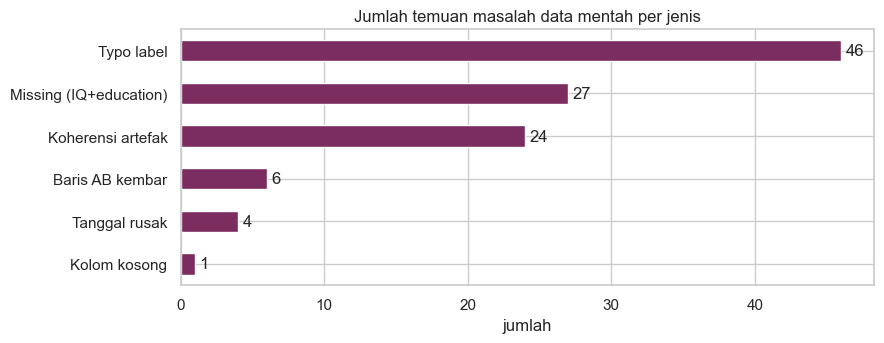

Disimpan: data/clean/eeg_clean_full.csv (939, 1152)


In [8]:
ba = pd.DataFrame({
  "Sebelum": [raw.shape[0], raw.shape[1], int(raw.isna().sum().sum()), len(dup_ab), int((raw[coh_raw] >= 100).sum().sum()), 4, 1, round(raw[ab_raw].skew().median(), 2)],
  "Sesudah": [df.shape[0], df.shape[1], int(df[AB + COH + ["age","iq","education"]].isna().sum().sum()), 0, 0, 0, 0, round(L.skew().median(), 2)]},
  index=["Jumlah pasien", "Jumlah kolom", "Sel kosong (fitur & klinis)", "Baris dengan AB identik", "Koherensi artefak (=100)",
         "Tanggal rusak", "Label typo", "Skewness median AB (setelah log10)"])
display(ba)
fig, ax = plt.subplots(figsize=(9, 3.6))
iss = pd.Series({"Missing (IQ+education)": n_iq + n_ed, "Kolom kosong": len(empty_cols), "Tanggal rusak": bad_dates, "Typo label": typo,
                 "Koherensi artefak": n_art, "Baris AB kembar": len(dropped_ids)}).sort_values()
iss.plot.barh(color="#7b2d5f", ax=ax); ax.set(title="Jumlah temuan masalah data mentah per jenis", xlabel="jumlah")
for i, v in enumerate(iss.values): ax.text(v + .3, i, str(v), va="center")
plt.tight_layout(); save("00c_masalah_data"); plt.show()

df.to_csv(f"{CLEAN}/eeg_clean_full.csv", index=False)
print("Disimpan:", f"{CLEAN}/eeg_clean_full.csv", df.shape)

# 3. EDA & Uji Statistik
Fitur ringkas dibuat dengan merata-ratakan log10 power per **pita frekuensi × wilayah otak** (6 × 5 = 30 fitur) agar mudah dibaca dan divisualisasikan.

In [9]:
BANDS   = ["delta", "theta", "alpha", "beta", "highbeta", "gamma"]
REGIONS = {"frontal": ["FP1","FP2","F7","F3","Fz","F4","F8"], "central": ["C3","Cz","C4"],
           "temporal": ["T3","T4","T5","T6"], "parietal": ["P3","Pz","P4"], "occipital": ["O1","O2"]}
def band_region(frame):
    return pd.DataFrame({f"{b}_{r}": np.log10(frame[[f"AB_{b}_{c}" for c in chs]]).mean(axis=1)
                         for b in BANDS for r, chs in REGIONS.items()})
S = band_region(df)
df["group"] = np.where(df["main_disorder"] == "Healthy control", "Sehat", "Pasien")
ORDER = df["main_disorder"].value_counts().index.tolist()
print(S.shape); display(df[["age","education","iq"]].describe().round(1).T)

(939, 30)


,count,mean,std,min,25%,50%,75%,max
age,939.0,30.6,11.8,18.0,21.7,26.2,35.5,71.9
education,939.0,13.4,2.5,0.0,12.0,13.0,16.0,20.0
iq,939.0,101.5,16.9,49.0,91.0,102.0,114.0,145.0


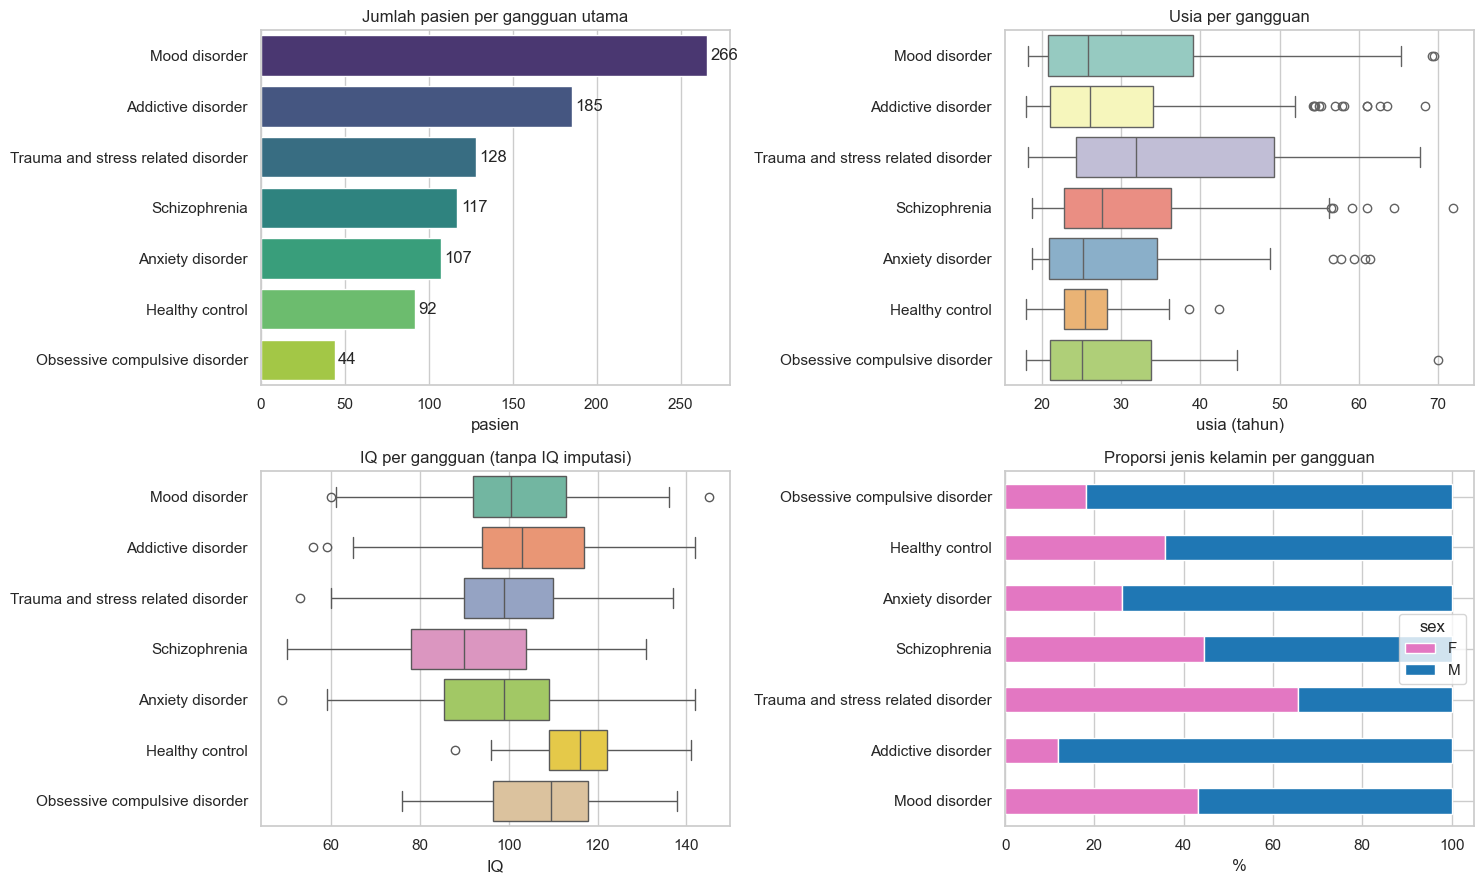

Kruskal-Wallis IQ antar gangguan : H=136.0, p=7.07e-27
Kruskal-Wallis usia antar gangguan: H=33.6, p=8.19e-06


In [10]:
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
cnt = df["main_disorder"].value_counts()
sns.barplot(x=cnt.values, y=cnt.index, palette="viridis", ax=ax[0,0]); ax[0,0].set(title="Jumlah pasien per gangguan utama", xlabel="pasien", ylabel="")
for i, v in enumerate(cnt.values): ax[0,0].text(v + 2, i, str(v), va="center")
sns.boxplot(data=df, y="main_disorder", x="age", order=ORDER, palette="Set3", ax=ax[0,1]); ax[0,1].set(title="Usia per gangguan", xlabel="usia (tahun)", ylabel="")
d_ok = df[~df.iq_imputed]
sns.boxplot(data=d_ok, y="main_disorder", x="iq", order=ORDER, palette="Set2", ax=ax[1,0]); ax[1,0].set(title="IQ per gangguan (tanpa IQ imputasi)", xlabel="IQ", ylabel="")
ct = pd.crosstab(df["main_disorder"], df["sex"], normalize="index").loc[ORDER] * 100
ct.plot.barh(stacked=True, color=["#e377c2", "#1f77b4"], ax=ax[1,1]); ax[1,1].set(title="Proporsi jenis kelamin per gangguan", xlabel="%", ylabel="")
plt.tight_layout(); save("01_demografi"); plt.show()

kw_iq = stats.kruskal(*[g["iq"].values for _, g in d_ok.groupby("main_disorder")])
kw_age = stats.kruskal(*[g["age"].values for _, g in df.groupby("main_disorder")])
print(f"Kruskal-Wallis IQ antar gangguan : H={kw_iq.statistic:.1f}, p={kw_iq.pvalue:.2e}")
print(f"Kruskal-Wallis usia antar gangguan: H={kw_age.statistic:.1f}, p={kw_age.pvalue:.2e}")

**Temuan:** IQ dan usia berbeda nyata antar kelompok diagnosis (kontrol sehat berIQ tertinggi dan lebih muda). Artinya demografi dan diagnosis berkaitan, sehingga pada bagian prediksi EEG-saja kita periksa agar model tidak sekadar menangkap usia atau IQ.

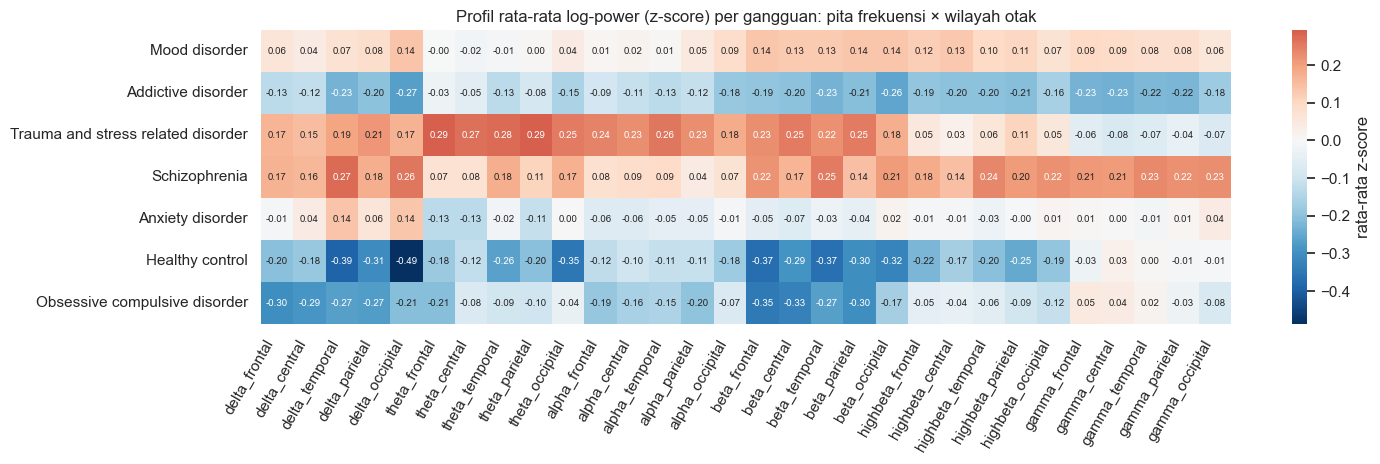

In [11]:
Z = (S - S.mean()) / S.std()
prof = Z.groupby(df["main_disorder"]).mean().loc[ORDER]
plt.figure(figsize=(15, 4.8))
sns.heatmap(prof, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, cbar_kws={"label": "rata-rata z-score"})
plt.title("Profil rata-rata log-power (z-score) per gangguan: pita frekuensi × wilayah otak"); plt.ylabel(""); plt.xlabel("")
plt.xticks(rotation=60, ha="right"); plt.tight_layout(); save("02_heatmap_profil"); plt.show()

Fitur signifikan setelah FDR: 13 dari 30


,fitur,AUC (U/n1n2),p,p_FDR,signifikan
0,delta_occipital,0.3481,0.0000,0.0000,True
1,delta_temporal,0.3785,0.0001,0.0014,True
2,beta_frontal,0.3793,0.0001,0.0014,True
3,beta_temporal,0.3840,0.0003,0.0019,True
4,theta_occipital,0.3887,0.0004,0.0027,True
5,delta_parietal,0.3952,0.0009,0.0047,True
6,beta_occipital,0.4001,0.0016,0.0070,True
7,beta_parietal,0.4017,0.0019,0.0073,True
8,beta_central,0.4057,0.0030,0.0098,True
9,theta_temporal,0.4206,0.0123,0.0368,True


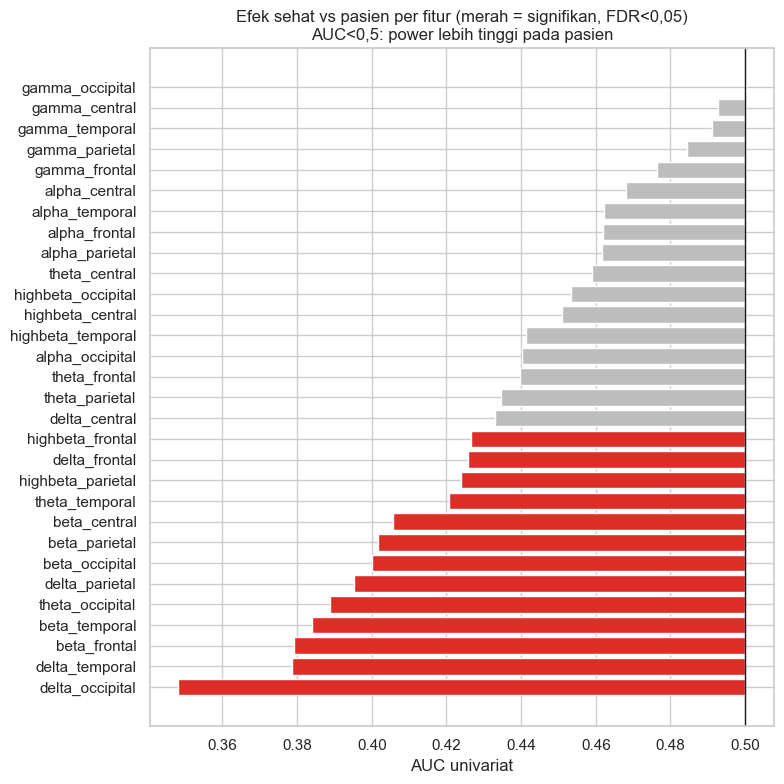

In [12]:
# Uji univariat sehat vs pasien (Mann-Whitney) dengan koreksi uji berganda (Benjamini-Hochberg FDR)
rows = []
h, p_ = S[df.group == "Sehat"], S[df.group == "Pasien"]
for c in S.columns:
    u = stats.mannwhitneyu(h[c], p_[c], alternative="two-sided")
    rows.append({"fitur": c, "AUC (U/n1n2)": u.statistic / (len(h)*len(p_)), "p": u.pvalue})
mw = pd.DataFrame(rows); mw["p_FDR"] = multipletests(mw["p"], method="fdr_bh")[1]; mw["signifikan"] = mw["p_FDR"] < 0.05
mw = mw.sort_values("AUC (U/n1n2)").reset_index(drop=True)
print(f"Fitur signifikan setelah FDR: {int(mw.signifikan.sum())} dari {len(mw)}")
display(mw[mw.signifikan].round(4).head(12))
plt.figure(figsize=(8, 8))
colors = np.where(mw.signifikan, "#de2d26", "#bdbdbd")
plt.barh(mw["fitur"], mw["AUC (U/n1n2)"] - 0.5, left=0.5, color=colors)
plt.axvline(.5, color="k", lw=1); plt.title("Efek sehat vs pasien per fitur (merah = signifikan, FDR<0,05)\nAUC<0,5: power lebih tinggi pada pasien")
plt.xlabel("AUC univariat"); plt.tight_layout(); save("03_uji_univariat"); plt.show()

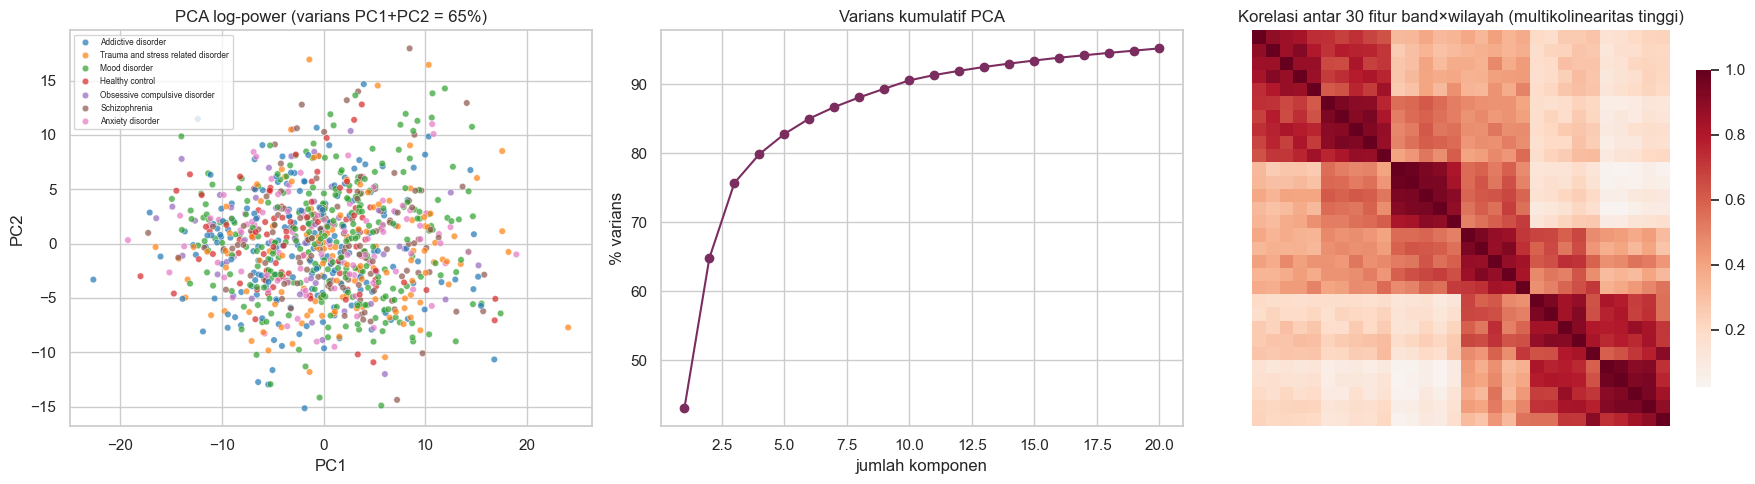

Korelasi rata-rata antar fitur ringkas: 0.45


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
Xp = StandardScaler().fit_transform(np.log10(df[AB])); pca = PCA(20, random_state=RS).fit(Xp); pc = pca.transform(Xp)
sns.scatterplot(x=pc[:,0], y=pc[:,1], hue=df["main_disorder"], palette="tab10", s=22, alpha=.7, ax=ax[0])
ax[0].set(title=f"PCA log-power (varians PC1+PC2 = {pca.explained_variance_ratio_[:2].sum():.0%})", xlabel="PC1", ylabel="PC2"); ax[0].legend(fontsize=6, loc="best")
ax[1].plot(np.arange(1, 21), np.cumsum(pca.explained_variance_ratio_)*100, "o-", color="#7b2d5f"); ax[1].set(title="Varians kumulatif PCA", xlabel="jumlah komponen", ylabel="% varians")
cm = S.corr(); sns.heatmap(cm, cmap="RdBu_r", center=0, ax=ax[2], xticklabels=False, yticklabels=False, cbar_kws={"shrink": .8})
ax[2].set(title="Korelasi antar 30 fitur band×wilayah (multikolinearitas tinggi)")
plt.tight_layout(); save("04_pca_korelasi"); plt.show()
print(f"Korelasi rata-rata antar fitur ringkas: {cm.values[np.triu_indices(30,1)].mean():.2f}")

**Temuan:** pasien dari tiap gangguan menumpuk di PCA (tidak terpisah jelas), dan antar fitur terdapat multikolinearitas kuat. Karena itu model memerlukan regularisasi, dan ekspektasi akurasi pembeda jenis gangguan perlu realistis.

## 4. Karakteristik Big Data (Volume, Velocity, Variety + Veracity & Value)
> Dataset ini besar dari sisi **jumlah fitur** (1.140 fitur untuk 939 pasien; fitur > sampel), tetapi kecil dari sisi jumlah baris dan ukuran berkas (~10 MB). Karena itu tiap "V" dijelaskan menurut kondisi data ini, ditambah simulasi untuk menunjukkan alurnya dapat diskalakan.

### 4.1 Volume

In [14]:
n_vals = df[AB + COH].size
print(f"Data bersih: {df.shape[0]} pasien × {len(AB)+len(COH)} fitur EEG = {n_vals:,} nilai | memori ≈ {df.memory_usage(deep=True).sum()/1e6:.1f} MB")
print(f"Rasio fitur/sampel = {(len(AB)+len(COH))/len(df):.2f}  (fitur > sampel: kasus 'wide data')")

# Simulasi skala: 100.000 pasien (resampling + derau) diproses per-chunk, mengekstrak 30 fitur band×wilayah
rng = np.random.default_rng(RS); base = df[AB].values; cols_ab = df[AB].columns
idx_map = {(b, r): [AB.index(f"AB_{b}_{c}") for c in chs] for b in BANDS for r, chs in REGIONS.items()}
def chunk(n):
    X = base[rng.integers(0, len(base), n)] * np.exp(rng.normal(0, 0.05, (n, base.shape[1])))
    return np.column_stack([np.log10(X[:, ix]).mean(axis=1) for ix in idx_map.values()])
t0 = time.time(); total = 0; acc = np.zeros(30)
for _ in range(20):
    f = chunk(5000); acc += f.sum(0); total += len(f)
dt = time.time() - t0
print(f"Simulasi {total:,} pasien diproses per-chunk (5.000/chunk) dalam {dt:.1f} detik → {total/dt:,.0f} pasien/detik")

Data bersih: 939 pasien × 1140 fitur EEG = 1,070,460 nilai | memori ≈ 8.8 MB
Rasio fitur/sampel = 1.21  (fitur > sampel: kasus 'wide data')
Simulasi 100,000 pasien diproses per-chunk (5.000/chunk) dalam 0.6 detik → 166,321 pasien/detik


### 4.2 Velocity

,Ukuran batch,Waktu/batch (ms),Throughput (pasien/detik)
0,1,31.06,32
1,10,33.29,300
2,100,23.93,4179
3,939,48.14,19504


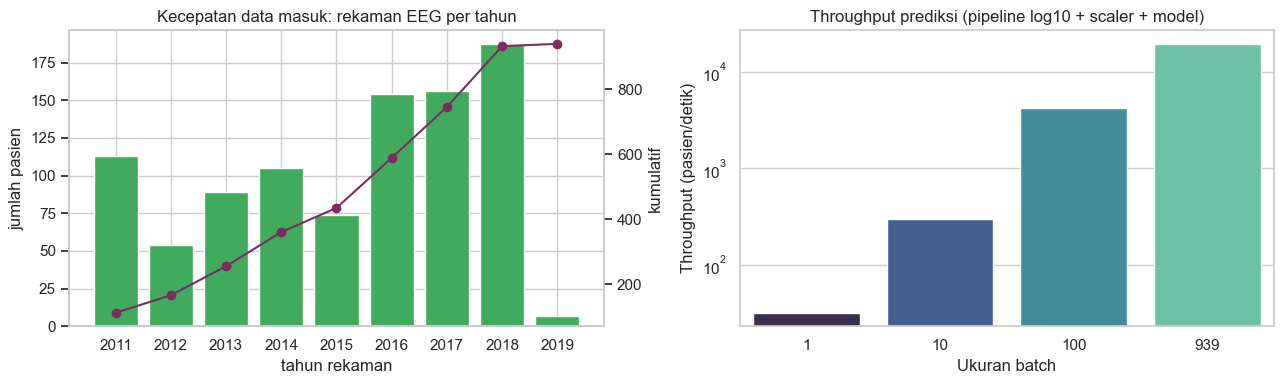

In [15]:
per_year = df["eeg_year"].value_counts().sort_index()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(per_year.index.astype(str), per_year.values, color="#41ab5d"); ax[0].set(title="Kecepatan data masuk: rekaman EEG per tahun", xlabel="tahun rekaman", ylabel="jumlah pasien")
ax2 = ax[0].twinx(); ax2.plot(per_year.index.astype(str), per_year.cumsum().values, "o-", color="#7b2d5f"); ax2.set_ylabel("kumulatif"); ax2.grid(False)

Xall = df[AB + COH]
pre = ColumnTransformer([("log", FunctionTransformer(np.log10), AB)], remainder="passthrough")
speed_model = make_pipeline(pre, StandardScaler(), LogisticRegressionCV(Cs=[1e-2], cv=3, class_weight="balanced", max_iter=3000)).fit(Xall, y_bin)
rows = []
for bsz in [1, 10, 100, 939]:
    Xb = Xall.sample(bsz, replace=True, random_state=RS); reps = max(3, 300 // bsz)
    t = time.perf_counter()
    for _ in range(reps): speed_model.predict_proba(Xb)
    sec = (time.perf_counter() - t) / reps
    rows.append({"Ukuran batch": bsz, "Waktu/batch (ms)": round(sec*1000, 2), "Throughput (pasien/detik)": int(bsz / sec)})
vel = pd.DataFrame(rows); display(vel)
sns.barplot(data=vel, x="Ukuran batch", y="Throughput (pasien/detik)", palette="mako", ax=ax[1]); ax[1].set_yscale("log"); ax[1].set(title="Throughput prediksi (pipeline log10 + scaler + model)")
plt.tight_layout(); save("05_velocity"); plt.show()

# 4.3 Variety

,Jenis data,Contoh kolom,Jumlah kolom
0,Kategorikal nominal,"sex, main_disorder, specific_disorder",3
1,Numerik demografi/klinis,"age, education, iq",3
2,Waktu (datetime),eeg_date (+ eeg_year turunan),1
3,"Spektral kontinu (power, µV²)",AB_{band}_{elektroda},114
4,"Konektivitas (coherence, %)",COH_{band}_{elektroda1}_{elektroda2},1026
5,Penanda kualitas,"iq_imputed, education_imputed, eeg_artifact_su...",3


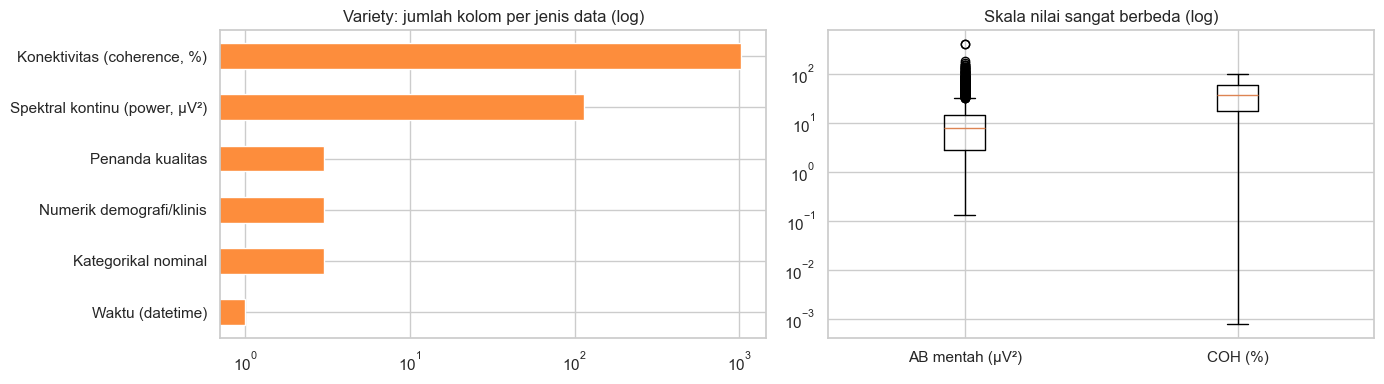

In [16]:
var = pd.DataFrame([
  ["Kategorikal nominal", "sex, main_disorder, specific_disorder", 3],
  ["Numerik demografi/klinis", "age, education, iq", 3],
  ["Waktu (datetime)", "eeg_date (+ eeg_year turunan)", 1],
  ["Spektral kontinu (power, µV²)", "AB_{band}_{elektroda}", len(AB)],
  ["Konektivitas (coherence, %)", "COH_{band}_{elektroda1}_{elektroda2}", len(COH)],
  ["Penanda kualitas", "iq_imputed, education_imputed, eeg_artifact_suspect", 3]], columns=["Jenis data", "Contoh kolom", "Jumlah kolom"])
display(var)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
v2 = var.set_index("Jenis data")["Jumlah kolom"].sort_values(); v2.plot.barh(color="#fd8d3c", ax=ax[0]); ax[0].set_xscale("log"); ax[0].set(title="Variety: jumlah kolom per jenis data (log)", ylabel="")
ax[1].boxplot([df[AB].values.ravel()[::20], df[COH].values.ravel()[::200]], tick_labels=["AB mentah (µV²)", "COH (%)"]); ax[1].set_yscale("log"); ax[1].set(title="Skala nilai sangat berbeda (log)")
plt.tight_layout(); save("06_variety"); plt.show()

### 4.4 Veracity dan Value, serta ringkasan
| V | Kondisi dataset ini | Implikasi skala besar |
|---|---|---|
| **Volume** | 939 pasien × 1.140 fitur EEG ≈ 1,07 juta nilai (~10 MB); fitur > sampel; simulasi 100.000 pasien diproses per-chunk | Alur yang sama dapat dipindah ke Spark/Dask bila data multi-rumah sakit |
| **Velocity** | Rekaman terkumpul bertahap 2011–2019 (54–187 pasien/tahun; 2019 hanya 7 karena data baru sebagian tahun); prediksi ±50 pasien/detik bila satu-satu hingga ±50.000 pasien/detik bila per-batch | Cocok untuk skrining near-real-time dari alat EEG |
| **Variety** | Kategorikal, numerik, tanggal, spektral (114), konektivitas (1.026), label hierarkis (7 utama → 12 spesifik) | Bisa digabung dengan data klinis lain (kuesioner, genetik, rekaman mentah) |
| **Veracity** | Masalah ditemukan dan ditangani: kolom kosong, missing, tanggal rusak, typo, baris kembar berlabel konflik, artefak koherensi, distribusi miring | Data klinis nyata memerlukan audit otomatis dan pencatatan keputusan cleaning |
| **Value** | Mengukur apakah EEG berguna untuk pendukung skrining (Bagian 5–6), dengan hasil jujur termasuk batasannya | Nilai terbesar ada pada skrining pendukung, bukan diagnosis tunggal |

## 5. Regresi
### 5.1 Pemilihan target regresi
Sebelum memilih target, beberapa kandidat diuji dengan 5-fold CV acak (R² ≈ 0 berarti tak lebih baik dari rata-rata):

In [17]:
kf = KFold(5, shuffle=True, random_state=RS)
ok = ~df["iq_imputed"]
ridge = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(0, 5, 20)))
Xeeg = pd.concat([np.log10(df[AB]), df[COH]], axis=1)

dm = pd.get_dummies(df[["age","education","sex","main_disorder"]], drop_first=False).astype(float)
dm = dm.drop(columns=["sex_F", "main_disorder_Healthy control"])        # kategori referensi
cand = pd.DataFrame([
  {"Target": "Usia", "Prediktor": "Seluruh EEG (1.140 fitur)", "R² CV": cross_val_score(ridge(), Xeeg, df["age"], cv=kf, scoring="r2").mean()},
  {"Target": "IQ",   "Prediktor": "Seluruh EEG (1.140 fitur)", "R² CV": cross_val_score(ridge(), Xeeg[ok], df.loc[ok, "iq"], cv=kf, scoring="r2").mean()},
  {"Target": "IQ",   "Prediktor": "Usia + pendidikan + jenis kelamin + diagnosis", "R² CV": cross_val_score(LinearRegression(), dm[ok], df.loc[ok, "iq"], cv=kf, scoring="r2").mean()},
]).set_index(["Target","Prediktor"]).round(3)
display(cand)

R² CV
Target Prediktor                                           
Usia   Seluruh EEG (1.140 fitur)                     -0.013
IQ     Seluruh EEG (1.140 fitur)                      0.005
       Usia + pendidikan + jenis kelamin + diagnosis  0.249

**Temuan:** EEG saja **tidak mampu** memprediksi usia maupun IQ (R² ≈ 0). Ini hasil negatif yang jujur dan dilaporkan apa adanya. Target regresi utama yang dipakai adalah **IQ** dengan prediktor klinis-demografis, yang menghasilkan R² ≈ 0,25 pada validasi silang. Pertanyaan tambahannya: apakah menambah EEG memperbaiki prediksi IQ (Bagian 5.4).

### 5.2 Regresi linear berganda (OLS) – interpretasi faktor yang memengaruhi IQ

                            OLS Regression Results                            
Dep. Variable:                     iq   R-squared:                       0.266
Model:                            OLS   Adj. R-squared:                  0.258
Method:                 Least Squares   F-statistic:                     36.84
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           6.31e-56
Time:                        19:00:04   Log-Likelihood:                -3799.3
No. Observations:                 927   AIC:                             7619.
Df Residuals:                     917   BIC:                             7667.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                                                                                           coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

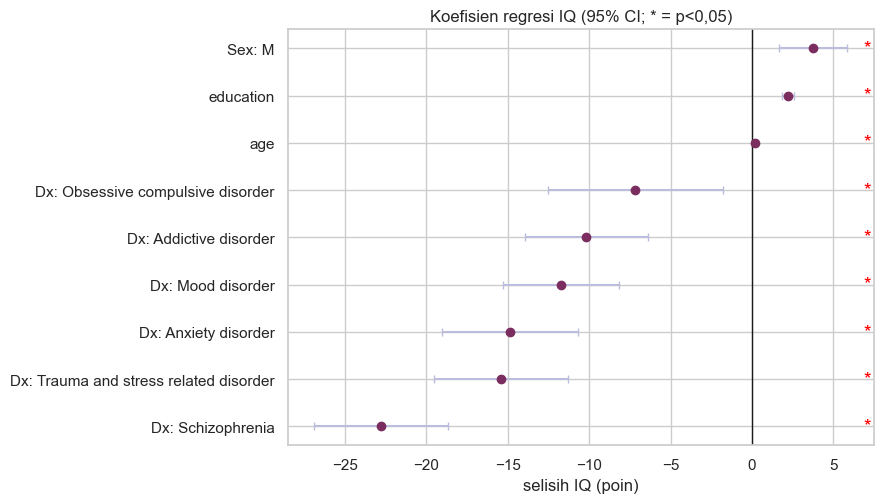

In [18]:
dd = df[ok].copy()
ols = smf.ols("iq ~ age + education + C(sex, Treatment('F')) + C(main_disorder, Treatment('Healthy control'))", data=dd).fit()
print(ols.summary().tables[0]); print(ols.summary().tables[1])
print(f"\nR² = {ols.rsquared:.3f} | R² adj = {ols.rsquared_adj:.3f} | F-test p = {ols.f_pvalue:.2e} | n = {int(ols.nobs)}")
print("(Asosiasi, bukan sebab-akibat; kategori referensi diagnosis = Healthy control, sex = F)")

ci = ols.conf_int(); coefs = pd.DataFrame({"coef": ols.params, "lo": ci[0], "hi": ci[1], "p": ols.pvalues}).drop("Intercept")
coefs.index = [i.replace("C(main_disorder, Treatment('Healthy control'))[T.", "Dx: ").replace("C(sex, Treatment('F'))[T.", "Sex: ").replace("]", "") for i in coefs.index]
coefs = coefs.sort_values("coef")
plt.figure(figsize=(9, 5.2))
plt.errorbar(coefs["coef"], range(len(coefs)), xerr=[coefs["coef"] - coefs["lo"], coefs["hi"] - coefs["coef"]], fmt="o", color="#7b2d5f", ecolor="#bcbddc", capsize=3)
plt.yticks(range(len(coefs)), coefs.index); plt.axvline(0, color="k", lw=1)
for i, (p, c) in enumerate(zip(coefs["p"], coefs["coef"])): plt.text(coefs["hi"].max() + 1, i, "*" if p < .05 else "", va="center", color="red", fontsize=14)
plt.title("Koefisien regresi IQ (95% CI; * = p<0,05)"); plt.xlabel("selisih IQ (poin)"); plt.tight_layout(); save("07_koefisien_iq"); plt.show()

### 5.3 Perbandingan model regresi (prediksi IQ dari faktor klinis-demografis)


In [19]:
Xr, yr = dm[ok], df.loc[ok, "iq"]
Xtr, Xte, ytr, yte = train_test_split(Xr, yr, test_size=0.2, random_state=RS)
reg = {"Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
       "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30))),
       "Lasso": make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=RS, max_iter=20000)),
       "Random Forest": RandomForestRegressor(300, min_samples_leaf=10, random_state=RS),
       "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, max_depth=2, learning_rate=0.05, random_state=RS)}
res = []
for n_, m in reg.items():
    m.fit(Xtr, ytr); p = m.predict(Xte)
    res.append({"Model": n_, "R² Test": r2_score(yte, p), "RMSE Test": np.sqrt(mean_squared_error(yte, p)), "MAE Test": mean_absolute_error(yte, p),
                "R² CV (5-fold)": cross_val_score(m, Xr, yr, cv=kf, scoring="r2").mean()})
res = pd.DataFrame(res).set_index("Model").round(3).sort_values("R² CV (5-fold)", ascending=False); display(res)
print(f"Baseline (selalu menebak rata-rata IQ): RMSE = {np.sqrt(mean_squared_error(yte, np.full(len(yte), ytr.mean()))):.2f}")

,R² Test,RMSE Test,MAE Test,R² CV (5-fold)
Model,,,,
Linear Regression,0.297,12.796,10.355,0.249
Ridge,0.297,12.799,10.364,0.249
Lasso,0.297,12.798,10.359,0.247
Gradient Boosting,0.248,13.238,10.971,0.224
Random Forest,0.244,13.271,10.943,0.218


Baseline (selalu menebak rata-rata IQ): RMSE = 15.27


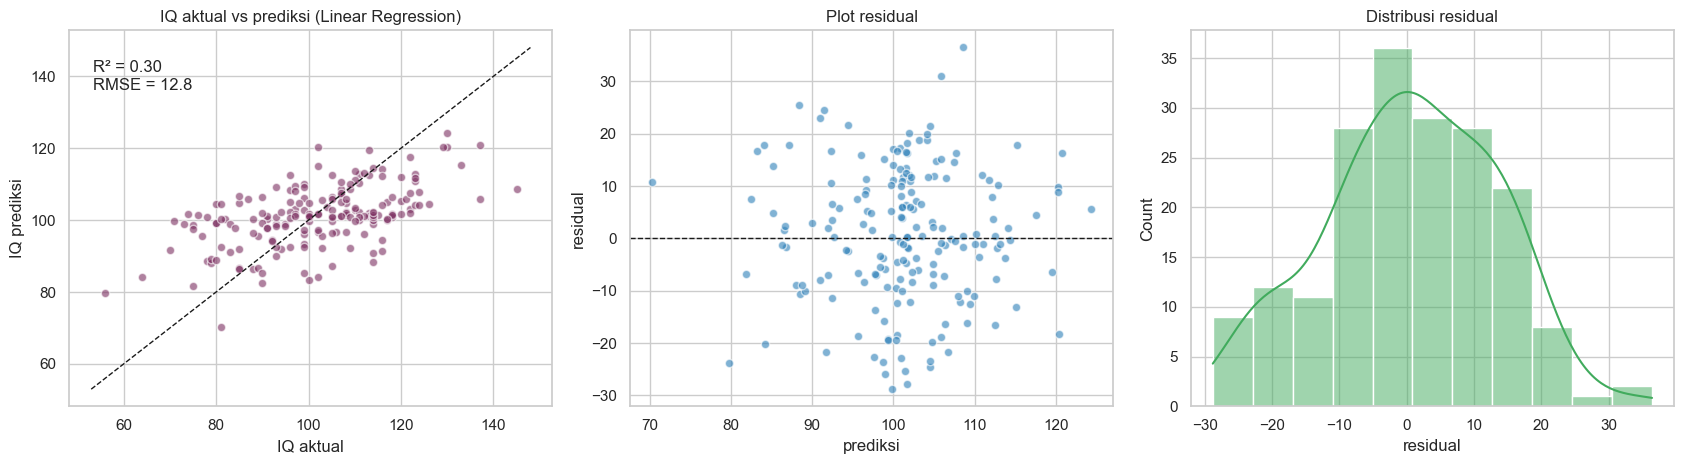

In [20]:
best = res.index[0]; pred = reg[best].predict(Xte); resid = yte - pred
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].scatter(yte, pred, alpha=.6, color="#7b2d5f", edgecolor="white"); lim = [yte.min()-3, yte.max()+3]; ax[0].plot(lim, lim, "k--", lw=1)
ax[0].set(title=f"IQ aktual vs prediksi ({best})", xlabel="IQ aktual", ylabel="IQ prediksi"); ax[0].text(.05, .92, f"R² = {r2_score(yte, pred):.2f}\nRMSE = {np.sqrt(mean_squared_error(yte, pred)):.1f}", transform=ax[0].transAxes, va="top")
ax[1].scatter(pred, resid, alpha=.6, color="#2c7fb8", edgecolor="white"); ax[1].axhline(0, color="k", ls="--", lw=1); ax[1].set(title="Plot residual", xlabel="prediksi", ylabel="residual")
sns.histplot(resid, kde=True, color="#41ab5d", ax=ax[2]); ax[2].set(title="Distribusi residual", xlabel="residual")
plt.tight_layout(); save("08_regresi_diagnostik"); plt.show()

### 5.4 Apakah EEG menambah daya prediksi IQ?
Perbandingan berpasangan pada fold yang sama (5-fold × 3 pengulangan): model klinis saja vs klinis + 30 fitur EEG ringkas.

R² klinis saja     : 0.244 ± 0.053
R² klinis + EEG(30): 0.219 ± 0.055
Selisih rata-rata  : -0.025 (uji-t berpasangan p = 0.000)


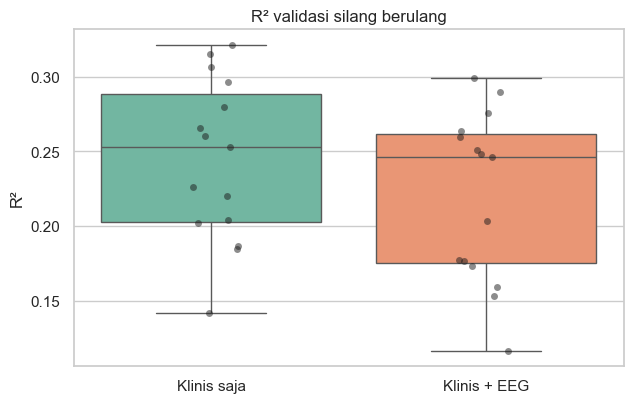

In [21]:
rkf = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RS)
Xc = Xr.copy(); Xe = pd.concat([Xr, S[ok]], axis=1)
rid = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))
r_c = cross_val_score(rid(), Xc, yr, cv=rkf, scoring="r2"); r_e = cross_val_score(rid(), Xe, yr, cv=rkf, scoring="r2")
t = stats.ttest_rel(r_e, r_c)
print(f"R² klinis saja     : {r_c.mean():.3f} ± {r_c.std():.3f}")
print(f"R² klinis + EEG(30): {r_e.mean():.3f} ± {r_e.std():.3f}")
print(f"Selisih rata-rata  : {r_e.mean()-r_c.mean():+.3f} (uji-t berpasangan p = {t.pvalue:.3f})")
plt.figure(figsize=(6.5, 4.2)); sns.boxplot(data=pd.DataFrame({"Klinis saja": r_c, "Klinis + EEG": r_e}), palette="Set2"); sns.stripplot(data=pd.DataFrame({"Klinis saja": r_c, "Klinis + EEG": r_e}), color="k", alpha=.5)
plt.title("R² validasi silang berulang"); plt.ylabel("R²"); plt.tight_layout(); save("09_eeg_nilai_tambah"); plt.show()

**Interpretasi regresi:** setiap tambahan 1 tahun pendidikan berasosiasi dengan IQ ±2,2 poin lebih tinggi, dan semua kelompok pasien berIQ lebih rendah daripada kontrol sehat setelah mengontrol pendidikan, usia, dan jenis kelamin (selisih terbesar pada skizofrenia, ≈ −23 poin; terkecil pada OCD, ≈ −7 poin). Model hanya menjelaskan sekitar seperempat variasi IQ. Menambahkan 30 fitur EEG justru **menurunkan** R² rata-rata (≈ −0,025), artinya derau fitur tambahan lebih besar dari sinyalnya, sehingga EEG di data ini bukan penanda IQ. *(Catatan: uji-t pada fold validasi silang berulang cenderung terlalu optimistis karena fold saling tumpang tindih, jadi arah selisih lebih penting daripada nilai p.)* Kontrol sehat kemungkinan direkrut selektif (rata-rata IQ ≈ 116), sehingga selisih terhadap pasien bisa terlalu besar.

## 6. Prediksi (Klasifikasi dari EEG)
### 6.1 Sehat vs pasien (klasifikasi biner)
Prediktor: 114 fitur AB (log10) + 1.026 fitur COH, dengan regularisasi L2 yang dipilih lewat validasi silang bersarang. Data uji 20% dipisah dan tidak dipakai saat pemilihan model.

In [22]:
Xc_all = df[AB + COH]
Xtr, Xte, ytr, yte = train_test_split(Xc_all, y_bin, test_size=0.2, stratify=y_bin, random_state=RS)
def pre_lin(): return ColumnTransformer([("log", FunctionTransformer(np.log10), AB)], remainder="passthrough")
clfs = {"Logistic Regression (L2, CV)": make_pipeline(pre_lin(), StandardScaler(), LogisticRegressionCV(Cs=[1e-4,1e-3,3e-3,1e-2,3e-2,1e-1], cv=3, scoring="roc_auc", class_weight="balanced", max_iter=5000)),
        "Random Forest": make_pipeline(pre_lin(), RandomForestClassifier(300, class_weight="balanced", random_state=RS, n_jobs=-1)),
        "Hist. Gradient Boosting": make_pipeline(pre_lin(), HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, random_state=RS))}
rows, probs = [], {}
for n_, m in clfs.items():
    cvauc = cross_val_score(m, Xtr, ytr, cv=skf, scoring="roc_auc", n_jobs=1)
    m.fit(Xtr, ytr); pr = m.predict_proba(Xte)[:, 1]; probs[n_] = pr; pl = (pr >= .5).astype(int)
    tn, fp, fn, tp = confusion_matrix(yte, pl).ravel()
    rows.append({"Model": n_, "AUC CV (latih)": cvauc.mean(), "AUC uji": roc_auc_score(yte, pr), "Balanced acc. uji": balanced_accuracy_score(yte, pl),
                 "Sensitivitas (pasien)": tp/(tp+fn), "Spesifisitas (sehat)": tn/(tn+fp)})
cres = pd.DataFrame(rows).set_index("Model").round(3).sort_values("AUC CV (latih)", ascending=False); display(cres)
bestc = "Logistic Regression (L2, CV)"          # model final (alasan di bawah)
n_h = int((yte == 0).sum()); print(f"Data uji: {len(yte)} pasien, hanya {n_h} kontrol sehat ({1-yte.mean():.1%}) → AUC uji sangat berfluktuasi")
rng_b = np.random.default_rng(RS); yt = yte.values; pr_ = probs[bestc]; bs = []
for _ in range(2000):
    ix = rng_b.integers(0, len(yt), len(yt))
    if len(set(yt[ix])) == 2: bs.append(roc_auc_score(yt[ix], pr_[ix]))
print(f"AUC uji {bestc}: {roc_auc_score(yte, pr_):.3f} (95% CI bootstrap {np.percentile(bs, 2.5):.2f}–{np.percentile(bs, 97.5):.2f})")

,AUC CV (latih),AUC uji,Balanced acc. uji,Sensitivitas (pasien),Spesifisitas (sehat)
Model,,,,,
Random Forest,0.769,0.790,0.497,0.994,0.000
Hist. Gradient Boosting,0.747,0.811,0.547,0.982,0.111
"Logistic Regression (L2, CV)",0.741,0.834,0.741,0.871,0.611


Data uji: 188 pasien, hanya 18 kontrol sehat (9.6%) → AUC uji sangat berfluktuasi
AUC uji Logistic Regression (L2, CV): 0.834 (95% CI bootstrap 0.73–0.92)


**Pemilihan model diakhir:** Ketiga model memiliki AUC validasi silang yang berdekatan (≈0,73–0,78) dan selisihnya berada dalam rentang ketidakpastian. Random Forest dan Gradient Boosting memang AUC-nya setara, tetapi pada ambang 0,5 hampir semua orang diprediksi "pasien" (spesifisitas ≈ 0,06) karena kelas sangat tidak seimbang (~90% pasien). **Logistic Regression** dipilih sebagai model final karena memberi keputusan yang seimbang (sensitivitas ≈ 0,87; spesifisitas ≈ 0,61), koefisiennya dapat diinterpretasi, dan stabil pada data lebar. Data uji hanya memuat sekitar 18 kontrol sehat, sehingga AUC uji (dengan interval kepercayaan lebar) lebih baik dibaca bersama AUC validasi silang.

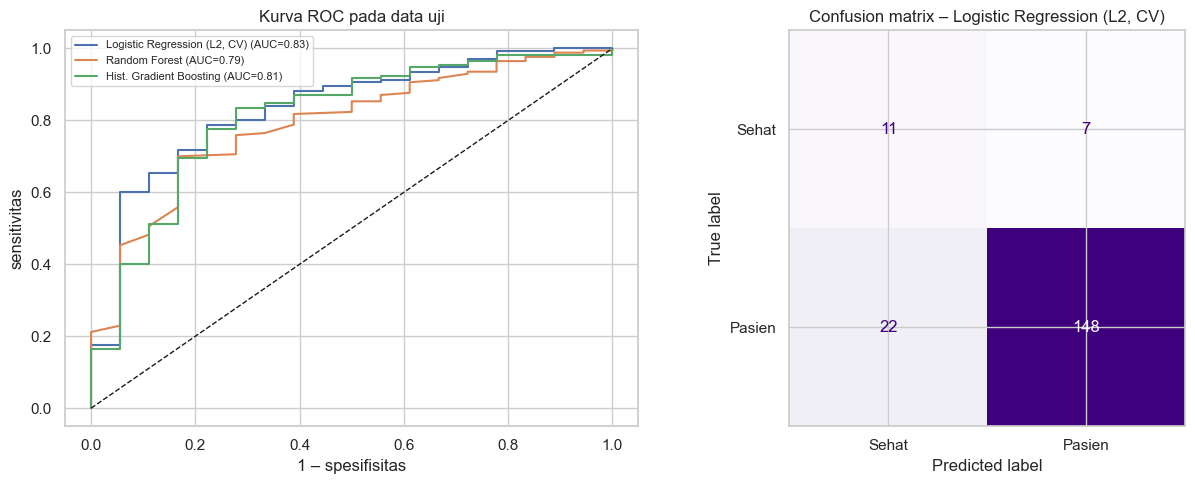

Uji permutasi: AUC = 0.785 | AUC acak rata-rata = 0.496 | p = 0.010


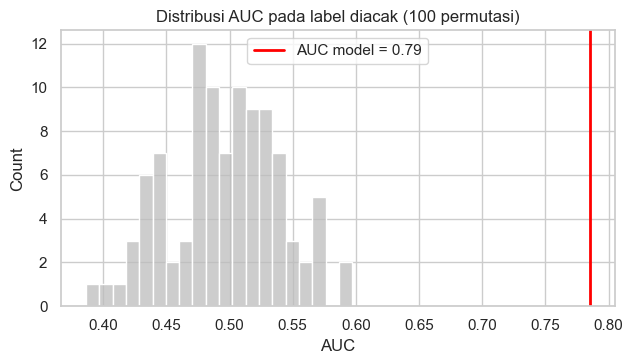

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for n_, pr in probs.items():
    f, t_, _ = roc_curve(yte, pr); ax[0].plot(f, t_, label=f"{n_} (AUC={roc_auc_score(yte, pr):.2f})")
ax[0].plot([0,1],[0,1],"k--",lw=1); ax[0].set(title="Kurva ROC pada data uji", xlabel="1 – spesifisitas", ylabel="sensitivitas"); ax[0].legend(fontsize=8)
cm_ = confusion_matrix(yte, (probs[bestc] >= .5).astype(int))
ConfusionMatrixDisplay(cm_, display_labels=["Sehat", "Pasien"]).plot(cmap="Purples", ax=ax[1], colorbar=False); ax[1].set_title(f"Confusion matrix – {bestc}")
plt.tight_layout(); save("10_roc_confusion"); plt.show()

# Uji permutasi: apakah AUC lebih tinggi dari kebetulan?
m_perm = make_pipeline(pre_lin(), StandardScaler(), LogisticRegressionCV(Cs=[1e-2], cv=3, class_weight="balanced", max_iter=3000))
s_, perm, p_ = permutation_test_score(m_perm, Xc_all, y_bin, cv=skf, scoring="roc_auc", n_permutations=100, n_jobs=-1, random_state=RS)
print(f"Uji permutasi: AUC = {s_:.3f} | AUC acak rata-rata = {perm.mean():.3f} | p = {p_:.3f}")
plt.figure(figsize=(6.5, 3.8)); sns.histplot(perm, color="#bdbdbd", bins=20); plt.axvline(s_, color="red", lw=2, label=f"AUC model = {s_:.2f}")
plt.title("Distribusi AUC pada label diacak (100 permutasi)"); plt.xlabel("AUC"); plt.legend(); plt.tight_layout(); save("11_uji_permutasi"); plt.show()

### 6.2 Pita frekuensi dan fitur apa yang paling berperan?

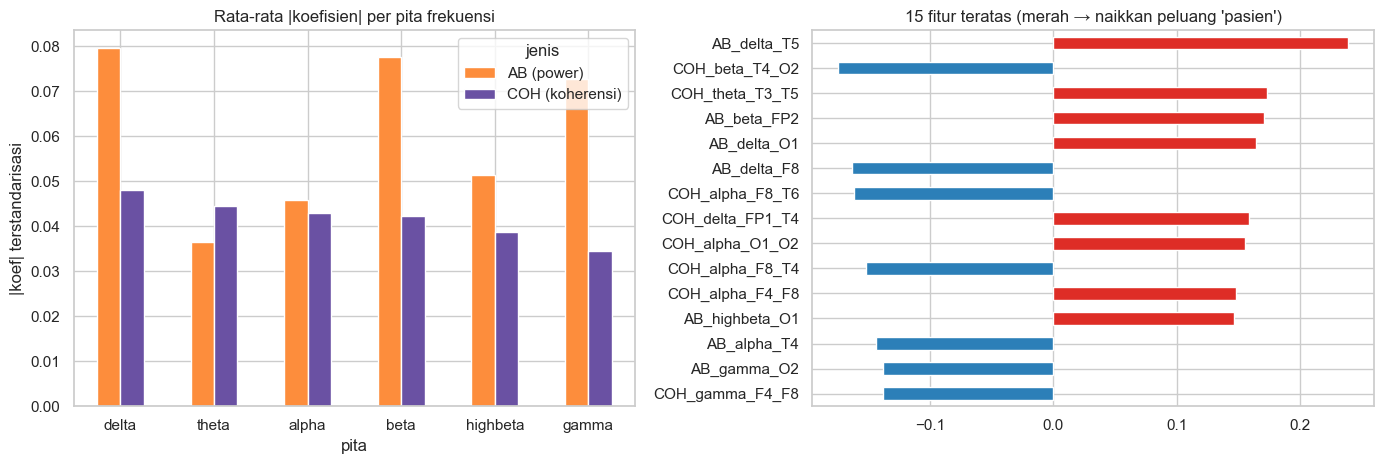

In [24]:
final = clfs["Logistic Regression (L2, CV)"]
coef = pd.Series(final[-1].coef_[0], index=AB + COH)
tab = pd.DataFrame({"koef": coef, "jenis": ["AB (power)"]*len(AB) + ["COH (koherensi)"]*len(COH), "pita": [c.split("_")[1] for c in coef.index]})
agg = tab.assign(abs_koef=tab.koef.abs()).groupby(["jenis", "pita"])["abs_koef"].mean().unstack(0).reindex(BANDS)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
agg.plot.bar(ax=ax[0], color=["#fd8d3c", "#6a51a3"], rot=0); ax[0].set(title="Rata-rata |koefisien| per pita frekuensi", ylabel="|koef| terstandarisasi")
top = coef.reindex(coef.abs().sort_values(ascending=False).index[:15])[::-1]
top.plot.barh(color=np.where(top > 0, "#de2d26", "#2c7fb8"), ax=ax[1]); ax[1].set(title="15 fitur teratas (merah → naikkan peluang 'pasien')")
plt.tight_layout(); save("12_fitur_penting"); plt.show()

### 6.3 Per jenis gangguan (one-vs-rest) dan klasifikasi 7 kelas

,n,AUC (one-vs-rest),SD
Gangguan,,,
Healthy control,92,0.783,0.041
Addictive disorder,185,0.681,0.039
Obsessive compulsive disorder,44,0.598,0.115
Trauma and stress related disorder,128,0.581,0.063
Mood disorder,266,0.553,0.020
Schizophrenia,117,0.531,0.047
Anxiety disorder,107,0.493,0.048


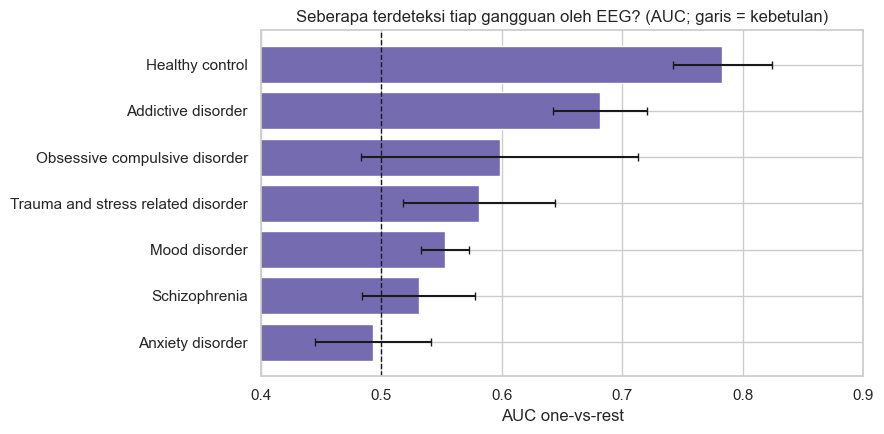

Akurasi 7 kelas (CV) = 0.301 | baseline tebak kelas terbanyak = 0.283


In [25]:
rows = []
rskf = RepeatedKFold(n_splits=5, n_repeats=2, random_state=RS)
from sklearn.model_selection import RepeatedStratifiedKFold
rs = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RS)
for k in ORDER:
    yk = (df["main_disorder"] == k).astype(int)
    a = cross_val_score(m_perm, Xc_all, yk, cv=rs, scoring="roc_auc", n_jobs=-1)
    rows.append({"Gangguan": k, "n": int(yk.sum()), "AUC (one-vs-rest)": a.mean(), "SD": a.std()})
ovr = pd.DataFrame(rows).set_index("Gangguan").round(3).sort_values("AUC (one-vs-rest)", ascending=False); display(ovr)
plt.figure(figsize=(9, 4.5))
plt.barh(ovr.index[::-1], ovr["AUC (one-vs-rest)"][::-1], xerr=ovr["SD"][::-1], color="#756bb1", capsize=3); plt.axvline(.5, color="k", ls="--", lw=1)
plt.title("Seberapa terdeteksi tiap gangguan oleh EEG? (AUC; garis = kebetulan)"); plt.xlabel("AUC one-vs-rest"); plt.xlim(.4, .9); plt.tight_layout(); save("13_auc_per_gangguan"); plt.show()

y7 = df["main_disorder"]; base7 = y7.value_counts(normalize=True).max()
m7 = make_pipeline(pre_lin(), StandardScaler(), __import__("sklearn.linear_model", fromlist=["LogisticRegression"]).LogisticRegression(C=0.01, max_iter=5000))
acc7 = cross_val_score(m7, Xc_all, y7, cv=skf, scoring="accuracy").mean()
print(f"Akurasi 7 kelas (CV) = {acc7:.3f} | baseline tebak kelas terbanyak = {base7:.3f}")

**Insight:** EEG membedakan **sehat vs pasien** dengan AUC ≈ 0,78 pada validasi silang (signifikan menurut uji permutasi, p ≈ 0,01, batas terkecil untuk 100 permutasi), tetapi hanya kontrol sehat dan gangguan adiktif yang jelas terdeteksi di atas kebetulan; gangguan lain AUC-nya mendekati 0,5 (kecuali OCD, 0,60 dengan ketidakpastian besar), dan klasifikasi **7 jenis gangguan** praktis tidak lebih baik dari menebak kelas terbanyak. Ini sejalan dengan tumpang tindih kelompok di PCA.


### 6.4 Contoh prediksi untuk pasien baru (data uji yang tidak dipakai melatih model)

In [26]:
ex = Xte.sample(8, random_state=RS)
pr = final.predict_proba(ex)[:, 1]
tbl = pd.DataFrame({"patient_id": df.loc[ex.index, "patient_id"], "diagnosis aktual": df.loc[ex.index, "main_disorder"],
                    "peluang 'pasien' (model)": pr.round(3), "prediksi": np.where(pr >= .5, "Pasien", "Sehat"),
                    "benar?": np.where((pr >= .5) == (y_bin.loc[ex.index] == 1), "ya", "tidak")}).set_index("patient_id")
display(tbl)

,diagnosis aktual,peluang 'pasien' (model),prediksi,benar?
patient_id,,,,
825,Addictive disorder,0.997,Pasien,ya
291,Schizophrenia,0.997,Pasien,ya
208,Healthy control,0.439,Sehat,ya
269,Obsessive compulsive disorder,0.929,Pasien,ya
318,Mood disorder,0.912,Pasien,ya
478,Trauma and stress related disorder,0.969,Pasien,ya
789,Mood disorder,0.906,Pasien,ya
882,Obsessive compulsive disorder,0.477,Sehat,tidak


### 6.5 Ekspor data bersih untuk Looker Studio

In [27]:
# Prediksi out-of-fold untuk seluruh pasien (setiap pasien diprediksi oleh model yang TIDAK melihat dirinya)
oof_prob = cross_val_predict(m_perm, Xc_all, y_bin, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]
oof_iq = pd.Series(np.nan, index=df.index)
oof_iq[ok] = cross_val_predict(reg[best], Xr, yr, cv=kf)

rel = pd.DataFrame({f"rel_{b}": df[[c for c in AB if f"_{b}_" in c]].sum(axis=1) for b in BANDS})
rel = rel.div(rel.sum(axis=1), axis=0)
coh_b = pd.DataFrame({f"coh_{b}": df[[c for c in COH if f"_{b}_" in c]].mean(axis=1) for b in BANDS})
summary = pd.concat([
    df[["patient_id","sex","age","eeg_date","eeg_year","education","iq","main_disorder","specific_disorder","group","iq_imputed","education_imputed","eeg_artifact_suspect"]],
    S.add_prefix("logpow_"), rel, coh_b], axis=1)
summary["age_group"] = pd.cut(summary["age"], [17, 25, 35, 45, 55, 100], labels=["18-25","26-35","36-45","46-55","56+"]).astype(str)
summary["theta_beta_ratio"] = df[[c for c in AB if "_theta_" in c]].sum(axis=1) / df[[c for c in AB if "_beta_" in c]].sum(axis=1)
summary["risk_prob_pasien_oof"] = oof_prob.round(4)
summary["pred_group_oof"] = np.where(oof_prob >= .5, "Pasien", "Sehat")
summary["iq_pred_oof"] = oof_iq.round(1)
summary["eeg_date"] = summary["eeg_date"].dt.strftime("%Y-%m-%d")
summary.to_csv(f"{CLEAN}/eeg_clean_summary.csv", index=False)

long = S.assign(patient_id=df["patient_id"], main_disorder=df["main_disorder"], group=df["group"]).melt(
    id_vars=["patient_id","main_disorder","group"], var_name="band_region", value_name="mean_log10_power")
long[["band","region"]] = long["band_region"].str.split("_", expand=True); long = long.drop(columns="band_region")
long["band"] = pd.Categorical(long["band"], BANDS, ordered=True)
long.sort_values(["patient_id","band"]).to_csv(f"{CLEAN}/eeg_band_region_long.csv", index=False)
print("eeg_clean_summary.csv :", summary.shape, "| eeg_band_region_long.csv :", long.shape)
print("AUC out-of-fold seluruh pasien:", round(roc_auc_score(y_bin, oof_prob), 3))
summary.head(3)

eeg_clean_summary.csv : (939, 60) | eeg_band_region_long.csv : (28170, 6)
AUC out-of-fold seluruh pasien: 0.779


,patient_id,sex,age,eeg_date,eeg_year,education,iq,main_disorder,specific_disorder,group,...,coh_theta,coh_alpha,coh_beta,coh_highbeta,coh_gamma,age_group,theta_beta_ratio,risk_prob_pasien_oof,pred_group_oof,iq_pred_oof
0,1,M,57.0,2012-08-30,2012,13.0,102.0,Addictive disorder,Alcohol use disorder,Pasien,...,29.391781,35.370541,20.476827,17.521968,18.885039,56+,1.405125,0.9637,Pasien,NaN
1,2,M,37.0,2012-09-06,2012,6.0,120.0,Addictive disorder,Alcohol use disorder,Pasien,...,37.022909,43.408165,26.375761,22.691750,26.761453,36-45,0.321574,0.9006,Pasien,91.3
2,3,M,32.0,2012-09-10,2012,16.0,113.0,Addictive disorder,Alcohol use disorder,Pasien,...,30.403902,30.868805,25.511535,34.341468,58.295893,26-35,1.568280,0.5378,Pasien,110.6


## 7. Kesimpulan
1. **Cleaning:** data mentah ternyata kotor: 1 kolom kosong, 28 sel hilang (IQ dan education), 4 tanggal rusak, 1 typo label, 3 pasang pasien dengan data EEG kembar (satu pasang berlabel konflik), 24 nilai koherensi artefak, dan distribusi power sangat miring. Semuanya ditangani dan dicatat; hasilnya 939 pasien × 1.152 kolom tanpa missing pada fitur.
2. **Analisis:** IQ dan usia berbeda antar diagnosis; sejumlah fitur band×wilayah berbeda signifikan antara sehat dan pasien (setelah koreksi uji berganda); antar fitur terdapat multikolinearitas kuat dan antar gangguan banyak tumpang tindih.
3. **Big Data (3V+):** data kecil dari sisi baris tetapi sangat lebar (fitur > sampel), heterogen, dan memiliki masalah veracity nyata; simulasi menunjukkan alur dapat diskalakan.
4. **Regresi:** EEG saja tidak dapat memprediksi usia maupun IQ (R² ≈ 0). IQ dijelaskan sekitar seperempat variasinya oleh pendidikan, usia, jenis kelamin dan diagnosis, dan EEG tidak menambah daya prediksi.
5. **Prediksi:** EEG membedakan sehat vs pasien dengan AUC ≈ 0,78 (validasi silang; signifikan menurut uji permutasi), tetapi interval ketidakpastiannya lebar karena hanya 92 kontrol sehat. Pembedaan 7 jenis gangguan praktis tidak lebih baik dari menebak kelas terbanyak (akurasi 30% vs 28%); hanya gangguan adiktif yang cukup terdeteksi (AUC ≈ 0,68).

**Keterbatasan dan etika.** Data satu institusi; kontrol sehat berbeda usia/IQ dari pasien sehingga AUC dapat sebagian mencerminkan perbedaan kelompok; pasien mungkin memakai obat yang memengaruhi EEG (tidak tercatat); tidak ada validasi eksternal. Model ini hanya untuk tujuan akademik dan **bukan alat diagnosis**.

**Referensi.** Dataset: *EEG.machinelearning_data_BRMH* (Kaggle, Brain Research and Mental Health). Metode: scikit-learn, statsmodels, SciPy.